In [1]:
# Import modules
import pandas as pd
import numpy as np
import json
import os
import plotly.io as pio
import plotly.express as px
import plotly.graph_objs as go
from plotly.subplots import make_subplots
pio.renderers.default='browser'

from behavioural_task_functions import load_behavioural_data, create_behavioural_dataframe, behavioural_data_diagnostics,behavioural_change_point_analysis, calculate_behavioural_learning_rate, plotting_behavioural_learning_rate, learning_rate_by_change_point, plot_behavioural_data

In [2]:
# Define participant, condition and task session characteristics
# Participants parameters
participant = 1
participant_str = str(participant).zfill(2)
list_subject_selected = [participant]

# Condition and task session parameters
# Condition 1 (c1) characteristics 
condition_1 = str(1).zfill(2)
c1_from_session, c1_to_session = 1, 20
c1_first_task_session_str = str(c1_from_session).zfill(2)
c1_last_task_session_str = str(c1_to_session).zfill(2)
c1_task_sessions = [str(session).zfill(2) for session in range(c1_from_session, c1_to_session + 1)]

# Condition 2 (c2) characteristics 
condition_2 = str(2).zfill(2)
c2_from_session, c2_to_session = 1, 16
c2_first_task_session_str = str(c2_from_session).zfill(2)
c2_last_task_session_str = str(c2_to_session).zfill(2)
c2_task_sessions = [str(session).zfill(2) for session in range(c2_from_session, c2_to_session + 1)]

In [3]:
# Loading adalearn task behavioural data using function created in behavioural_task_functions
adalearn_data_c1 = load_behavioural_data(participant_str, condition_1, c1_task_sessions)
adalearn_data_c2 = load_behavioural_data(participant_str, condition_2, c2_task_sessions)

/home/aaron/Documents/Python/Ada_Learn/Analysis/Analysis_scripts_functions
/home/aaron/Documents/Python/Ada_Learn/VNS Ada_Learn/Data/sub-01/ses-01
/home/aaron/Documents/Python/Ada_Learn/VNS Ada_Learn/Data/sub-01/ses-01
/home/aaron/Documents/Python/Ada_Learn/VNS Ada_Learn/Data/sub-01/ses-02


In [4]:
# Creating and loading adalearn task beahvioural data into a DataFrame using function created in behavioural_task_functions
adalearn_data_c1_df = create_behavioural_dataframe(adalearn_data_c1)
adalearn_data_c2_df = create_behavioural_dataframe(adalearn_data_c2)

In [5]:
# Checking whether expected quantities are present in the data (e.g. number of unique task sessions, number of outcome presentations within each task session)
adalearn_c1_diagnostics = behavioural_data_diagnostics(adalearn_data_c1_df, c1_task_sessions)
adalearn_c2_diagnostics = behavioural_data_diagnostics(adalearn_data_c2_df, c2_task_sessions)

The task sessions in the data file are: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
There are the expected number of task sessions: 20 / 20
Task session 1 has exactly 75 trials.
Task session 2 has exactly 75 trials.
Task session 3 has exactly 75 trials.
Task session 4 has exactly 75 trials.
Task session 5 has exactly 75 trials.
Task session 6 has exactly 75 trials.
Task session 7 has exactly 75 trials.
Task session 8 has exactly 75 trials.
Task session 9 has exactly 75 trials.
Task session 10 has exactly 75 trials.
Task session 11 has exactly 75 trials.
Task session 12 has exactly 75 trials.
Task session 13 has exactly 75 trials.
Task session 14 has exactly 75 trials.
Task session 15 has exactly 75 trials.
Task session 16 has exactly 75 trials.
Task session 17 has exactly 75 trials.
Task session 18 has exactly 75 trials.
Task session 19 has exactly 75 trials.
Task session 20 has exactly 75 trials.
Number of True values in 'change_point' for each task session:
task_ses

In [6]:
# Plotting the raw data obtained from the adalearn task using function in behavioural_task_functions
adalearn_c1_fig = plot_behavioural_data(adalearn_data_c1_df, participant, condition_1)
adalearn_c2_fig = plot_behavioural_data(adalearn_data_c2_df, participant, condition_2)

In [7]:
# Identifying change points within behavioural data for each task session using function in behavioural_task_functions
c1_change_point_num, c1_change_point_by_sess, c1_change_point_indices = behavioural_change_point_analysis(adalearn_data_c1_df)
c2_change_point_num, c2_change_point_by_sess, c2_change_point_indices = behavioural_change_point_analysis(adalearn_data_c2_df)

In [8]:
# Calculate behavioural learning rate using function in behavioural_task_functions
adalearn_data_c1_df = calculate_behavioural_learning_rate(adalearn_data_c1_df)
adalearn_data_c2_df = calculate_behavioural_learning_rate(adalearn_data_c2_df)

In [9]:
# Plotting behavioural learning rate using function in behavioural_task_functions
c1_learning_rate_fig = plotting_behavioural_learning_rate(adalearn_data_c1_df, condition_1)
c2_learning_rate_fig = plotting_behavioural_learning_rate(adalearn_data_c2_df, condition_2)  

In [10]:
# Plotting average behavioural learning rate dynamics locked to change point using function in behavioural_task_functions
c1_learning_rate_by_cp, c1_avg_learning_rate_cp = learning_rate_by_change_point(adalearn_data_c1_df, c1_change_point_indices, participant, condition_1, pre=2, post=10)
c2_learning_rate_by_cp, c2_avg_learning_rate_cp = learning_rate_by_change_point(adalearn_data_c2_df, c2_change_point_indices, participant, condition_2, pre=2, post = 10)

Total number of traces added to the individual plot: 59
Total number of traces added to the individual plot: 44


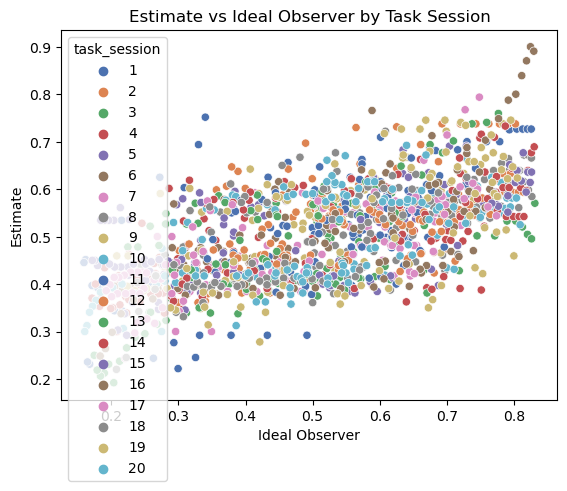

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'adalearn_data_c1_df' is your DataFrame

# Create a scatter plot with seaborn
sns.scatterplot(data=adalearn_data_c1_df, x='ideal_observer', y='estimate', hue='task_session', palette='deep')

# Add title and labels
plt.title('Estimate vs Ideal Observer by Task Session')
plt.xlabel('Ideal Observer')
plt.ylabel('Estimate')
plt.show()